[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_returns_path/BA_L2_returns_path.ipynb)

# BA_L2_returns_path: From Prices to Returns: Bitcoin, 2018-2026

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Bitcoin daily close on a log scale and daily log returns in percent, 1 January 2018 to 18 September 2026, with the worst day and the share of days beyond plus or minus 5%.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

`close_cal(sym, start)` keeps each asset on its own calendar: crypto trades every day; for the S&P 500 and gold only
Monday–Friday closes are kept and repeated closes (holidays filled with the last price) are removed.
`log_returns(sym)` gives the daily log returns in percent, $r_t = 100(\ln P_t - \ln P_{t-1})$, of 2018–2026.

**How to read the chart.** Top: the price trends and swings over the years. Bottom: the daily returns stay around zero,
with bursts of large moves; the dotted lines mark $\pm 5\%$ and the arrow the worst day.

In [5]:
from scipy import stats
import statsmodels.api as sm


def close_cal(sym, start, end=END):
    # closes on the asset's own calendar: crypto every day; S&P 500 and gold Monday-Friday, repeated closes removed
    s = daily(sym, end).loc[start:]
    if not sym.endswith('.CC'):
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


def log_returns(sym, start='2017-12-31', first='2018-01-01', end=END):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1}), from `first`
    return (100 * np.log(close_cal(sym, start, end)).diff()).dropna().loc[first:]

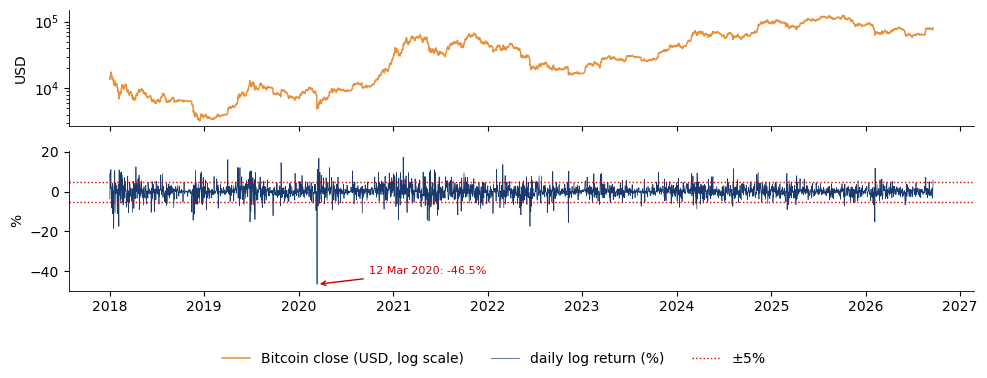

3,183 daily log returns, 01 Jan 2018 - 18 Sep 2026; sd 3.355%
Worst day 12 Mar 2020: -46.5%; best day 08 Feb 2021: +17.2%
Days with |r| > 5%: 340 (10.7%)
Sum of the daily log returns 174.3 = 100 ln(P_end / P_start) = 174.3


In [6]:
# Bitcoin: from prices to daily log returns, 2018-2026
p_btc18 = close_cal('BTC-USD.CC', '2017-12-31')
r_btc18 = log_returns('BTC-USD.CC')
fig, ax = plt.subplots(2, 1, figsize=(10, 3.8), sharex=True, gridspec_kw={'height_ratios': [1, 1.2]})
ax[0].plot(p_btc18.loc['2018':].index, p_btc18.loc['2018':], color=BTC, lw=1.1, label='Bitcoin close (USD, log scale)')
ax[0].set_yscale('log'); ax[0].set_ylabel('USD')
ax[1].plot(r_btc18.index, r_btc18, color=BLUE, lw=0.5, label='daily log return (%)')
ax[1].axhline(5, color=RED, ls=':', lw=1, label=r'$\pm 5\%$'); ax[1].axhline(-5, color=RED, ls=':', lw=1)
wd = r_btc18.idxmin()
ax[1].annotate(f'{wd:%d %b %Y}: {r_btc18.min():.1f}%', xy=(wd, r_btc18.min()), xytext=(wd + pd.Timedelta(days=200), r_btc18.min() + 5),
               fontsize=8, color=RED, arrowprops=dict(arrowstyle='->', color=RED))
ax[1].set_ylabel('%')
legend_below(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l2_returns_path')

print(f'{len(r_btc18):,} daily log returns, {r_btc18.index[0]:%d %b %Y} - {r_btc18.index[-1]:%d %b %Y}; sd {r_btc18.std():.3f}%')
print(f'Worst day {r_btc18.idxmin():%d %b %Y}: {r_btc18.min():.1f}%; best day {r_btc18.idxmax():%d %b %Y}: {r_btc18.max():+.1f}%')
print(f'Days with |r| > 5%: {int((r_btc18.abs() > 5).sum())} ({100 * (r_btc18.abs() > 5).mean():.1f}%)')
print(f'Sum of the daily log returns {r_btc18.sum():.1f} = 100 ln(P_end / P_start) = {100 * np.log(p_btc18.iloc[-1] / p_btc18.iloc[0]):.1f}')